<a href="https://colab.research.google.com/github/SkyWarLimit/244107020218-mobile-course/blob/main/JS08/JS08_Tugas1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

# 1. Load dataset
df = pd.read_csv('CC_Customer_Dataset.csv')

In [2]:
# 2. Prapemrosesan: Membuang kolom yang tidak relevan (seperti ID/Key)
# Sesuaikan nama kolom identifier dengan yang ada di dataset Anda, umumnya 'Sl_No' dan 'Customer Key'
X = df.drop(['Sl_No', 'Customer Key'], axis=1)

# 3. Standarisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [3]:
# Membangun model Agglomerative Clustering
# Kita gunakan ward linkage dan metric euclidean yang merupakan standar hierarkikal
agg_cluster = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
agg_labels = agg_cluster.fit_predict(X_scaled)

# Menyimpan hasil label cluster kembali ke dalam dataframe aslinya
df['Cluster'] = agg_labels

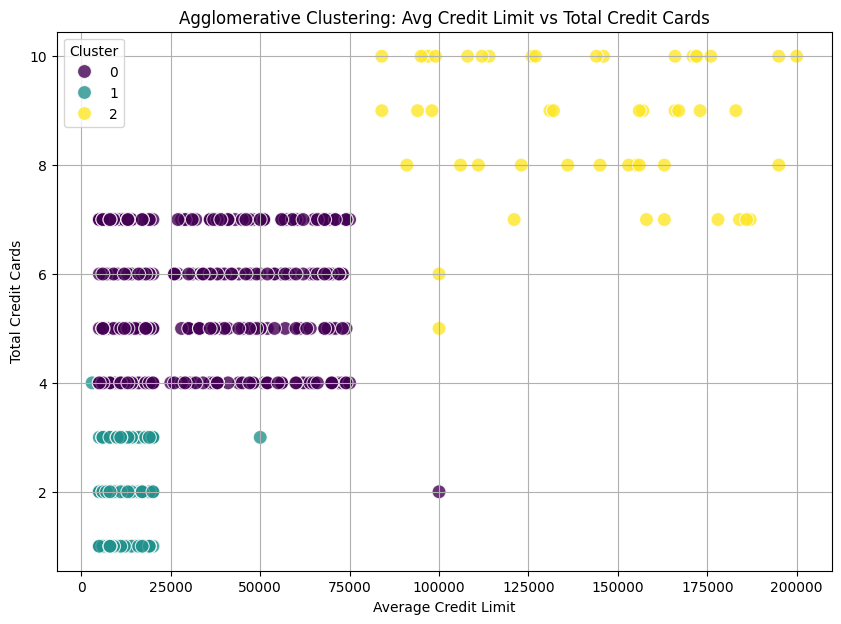

In [4]:
# Membuat Scatterplot
plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=df,
    x='Avg_Credit_Limit',
    y='Total_Credit_Cards', # Sesuaikan kapitalisasi huruf jika di dataset tertulis 'Total_credit_card'
    hue='Cluster',
    palette='viridis',
    s=100,
    alpha=0.8
)
plt.title('Agglomerative Clustering: Avg Credit Limit vs Total Credit Cards')
plt.xlabel('Average Credit Limit')
plt.ylabel('Total Credit Cards')
plt.grid(True)
plt.show()

In [5]:
# Menghitung Silhouette Score dan Davies-Bouldin Index (DBI)
sil_score = silhouette_score(X_scaled, agg_labels)
dbi_score = davies_bouldin_score(X_scaled, agg_labels)

print("=== Evaluasi Agglomerative Clustering ===")
print(f"Silhouette Score: {sil_score:.4f}")
print(f"Davies-Bouldin Index (DBI): {dbi_score:.4f}")

=== Evaluasi Agglomerative Clustering ===
Silhouette Score: 0.5148
Davies-Bouldin Index (DBI): 0.6810
